In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)


In [2]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw" / "privacy_reviews"

train = pd.read_csv(DATA_DIR / "original_12756.csv")
val = pd.read_csv(DATA_DIR / "val_1595.csv")
test = pd.read_csv(DATA_DIR / "test_1594.csv")

print("Training:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Training: (12756, 3)
Validation: (1595, 3)
Test: (1594, 3)


In [3]:
# Input features
X_train = train["Review"]
X_val = val["Review"]

# Target labels
y_train = train["Label"]
y_val = val["Label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Target classes:", sorted(y_train.unique()))

Training samples: 12756
Validation samples: 1595
Target classes: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
rf_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [5]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [6]:
# Predict validation labels
y_val_pred = rf_pipeline.predict(X_val)

# Calculate validation accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Random Forest Validation Accuracy:",
      round(val_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ],
    zero_division=0
))

Random Forest Validation Accuracy: 84.64 %

Classification Report:

                    precision    recall  f1-score   support

   Feature Request       0.83      0.80      0.82       360
        Bug Report       0.80      0.81      0.81       421
Privacy-Irrelevant       0.88      0.88      0.88       814

          accuracy                           0.85      1595
         macro avg       0.84      0.83      0.83      1595
      weighted avg       0.85      0.85      0.85      1595



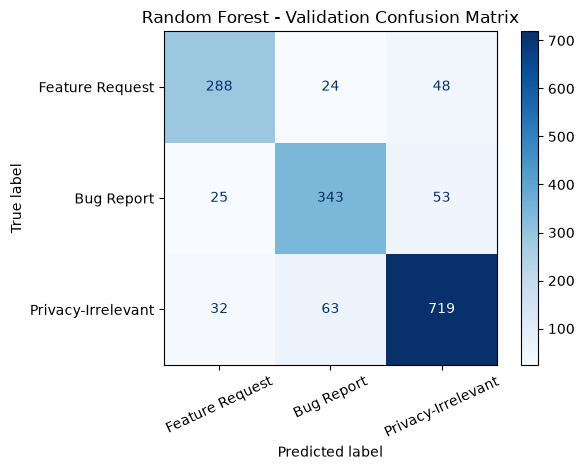

In [7]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ]
)

disp.plot(cmap="Blues", xticks_rotation=25)

plt.title("Random Forest - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Random Forest - Validation Results

- Dataset: Social Media Privacy Reviews
- Training samples: 12,756
- Validation samples: 1,595
- Feature extraction: TF-IDF
- Classifier: Random Forest
- Number of estimators: 200
- Class weighting: Balanced

### Performance

- Validation Accuracy: 84.64%
- Macro Precision: 0.84
- Macro Recall: 0.83
- Macro F1-score: 0.83

### Observation

Random Forest achieved slightly higher validation accuracy
than Naive Bayes. It showed improved recall for Bug Reports,
while performance on the other classes remained comparable.